# MPC con $x^\top P x$ vs. MPC con la red $V_\psi$

Dos MPC no lineales idénticos (mismo horizonte $N$, mismo modelo, mismas restricciones) que solo difieren en el **costo terminal**:

- **clásico**: $V_f(x) = x^\top P x$, con $P$ de la ecuación de Riccati del sistema linealizado.
- **red**: $V_f(x) = V_\psi(x) = x^\top P x \cdot e^{\varphi_\theta(x)}$, aprendida con iteración de valor (`valor_aprendido.py`).

Las animaciones son el `render` del environment de Gymnasium. Las líneas rojas marcan los topes del riel ($\pm 0.5$ m).

In [1]:
import sys, time, io
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Image
from PIL import Image as PILImage, ImageDraw, ImageFont

RAIZ = Path.cwd().parent if Path.cwd().name == "Inciso_A" else Path.cwd()
sys.path += [str(RAIZ / "simulador"), str(RAIZ / "Inciso_A")]

from pendulo_env import PenduloEnv, ParametrosPlanta
from mpc_no_lineal import MPCNoLineal, riccati, costo_terminal_cuadratico
from valor_aprendido import cargar

## Los dos costos terminales

In [2]:
p = ParametrosPlanta()
P, _ = riccati(p)
red, _, _ = cargar(RAIZ / "Inciso_A" / "modelos" / "V_psi_N5_s0.pt")

COSTOS_TERMINALES = {
    "x'Px": costo_terminal_cuadratico(P),
    "V_psi": red.a_casadi(),
}

## Simular en lazo cerrado

En cada paso de 20 ms el MPC resuelve su problema y aplica la primera fuerza. Medimos cuánto tarda cada `solve` (el tiempo de inferencia del controlador).
Igual que en el barrido de `visualizaciones.py`, el sistema **se estabiliza** si en 5 s no se cae ni sale del riel y termina con $|\theta| < 0.05$ y $|x| < 0.1$.

In [3]:
def simular(N, costo_terminal, estado0, pasos=250):
    env = PenduloEnv(p, render_mode="rgb_array")
    mpc = MPCNoLineal(p, N=N, costo_terminal=costo_terminal)
    estado, _ = env.reset(options={"estado": estado0})

    cuadros, tiempos = [env.render()], []
    resultado = None
    for _ in range(pasos):
        inicio = time.perf_counter()
        F = mpc.solve(estado)
        tiempos.append(time.perf_counter() - inicio)

        estado, _, terminado, _, info = env.step([F])
        cuadros.append(env.render())
        if terminado:
            resultado = "sale del riel" if info["fuera_riel"] else "se cae"
            break

    if resultado is None:
        quieto = abs(estado[2]) < 0.05 and abs(estado[0]) < 0.1
        resultado = "estabiliza" if quieto else "no converge"
    env.close()
    return cuadros, np.array(tiempos), resultado

Para ver las dos corridas juntas, armamos un GIF con el clásico a la izquierda y la red a la derecha.

In [4]:
FUENTE = ImageFont.load_default(size=22)

def dibujar(cuadro, titulo, color):
    img = PILImage.fromarray(cuadro)
    d = ImageDraw.Draw(img)
    escala = img.width / (2 * (p.x_max + 0.1))         # píxeles por metro, como el render de CartPole
    for x in (-p.x_max, p.x_max):                      # topes del riel
        px = img.width / 2 + x * escala
        d.line([(px, 230), (px, 330)], fill=(220, 50, 50), width=3)
    d.text((12, 10), titulo, fill=color, font=FUENTE)
    return img.resize((img.width // 2, img.height // 2))

def gif_lado_a_lado(corridas):
    largo = max(len(c[0]) for c in corridas.values())
    imagenes = []
    for k in range(0, largo + 25, 2):                  # un cuadro cada 2 pasos -> 25 fps, tiempo real
        mitades = []
        for nombre, (cuadros, _, resultado) in corridas.items():
            if k < len(cuadros):
                mitades.append(dibujar(cuadros[k], nombre, (40, 40, 40)))
            else:                                       # ya terminó: queda congelado con el resultado
                color = (20, 150, 20) if resultado == "estabiliza" else (210, 40, 40)
                mitades.append(dibujar(cuadros[-1], f"{nombre}: {resultado}", color))
        lienzo = PILImage.new("RGB", (mitades[0].width * 2 + 6, mitades[0].height), "white")
        lienzo.paste(mitades[0], (0, 0))
        lienzo.paste(mitades[1], (mitades[0].width + 6, 0))
        imagenes.append(lienzo)

    buffer = io.BytesIO()
    imagenes[0].save(buffer, format="GIF", save_all=True, append_images=imagenes[1:], duration=40, loop=0)
    return buffer.getvalue()

In [5]:
def comparar(N, x0=0.0, v0=0.0, theta0=0.0, omega0=0.0):
    estado0 = [x0, v0, theta0, omega0]
    corridas = {nombre: simular(N, vf, estado0) for nombre, vf in COSTOS_TERMINALES.items()}

    print(f"N = {N}, estado inicial [x, x', theta, theta'] = {np.round(estado0, 2).tolist()}")
    for nombre, (cuadros, tiempos, resultado) in corridas.items():
        print(f"  {nombre:6s} {resultado:14s} duró {(len(cuadros) - 1) * p.dt:.2f} s   "
              f"solve: medio {1e3 * tiempos.mean():.1f} ms, máximo {1e3 * tiempos.max():.1f} ms")
    display(Image(data=gif_lado_a_lado(corridas), format="gif"))
    return {nombre: tiempos for nombre, (_, tiempos, _) in corridas.items()}

## Casos donde la red estabiliza y el clásico no

Salen del barrido de la región de recuperación (`figuras/casos_vpsi_vs_xpx.json`): el carro arranca en $x=0$ con $\dot\theta=0$. En todos, el MPC con $x^\top P x$ falla porque **saca el carro del riel**: el costo cuadrático no sabe que el riel termina, y $V_\psi$ lo aprendió.

N = 1, estado inicial [x, x', theta, theta'] = [0.0, 1.5, -0.2, 0.0]
  x'Px   sale del riel  duró 0.54 s   solve: medio 2.3 ms, máximo 3.1 ms
  V_psi  estabiliza     duró 5.00 s   solve: medio 3.5 ms, máximo 4.6 ms


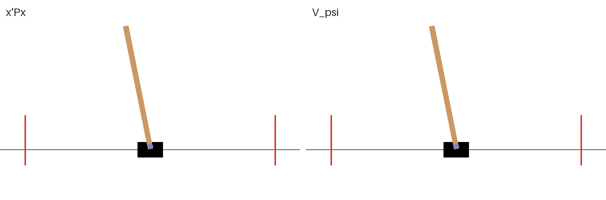

N = 2, estado inicial [x, x', theta, theta'] = [0.0, 0.21, 0.3, 0.0]
  x'Px   sale del riel  duró 0.68 s   solve: medio 2.6 ms, máximo 3.6 ms
  V_psi  estabiliza     duró 5.00 s   solve: medio 4.1 ms, máximo 11.0 ms


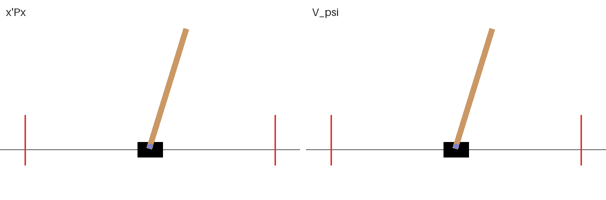

N = 3, estado inicial [x, x', theta, theta'] = [0.0, 0.0, -0.4, 0.0]
  x'Px   sale del riel  duró 0.60 s   solve: medio 3.0 ms, máximo 4.7 ms
  V_psi  estabiliza     duró 5.00 s   solve: medio 4.2 ms, máximo 9.3 ms


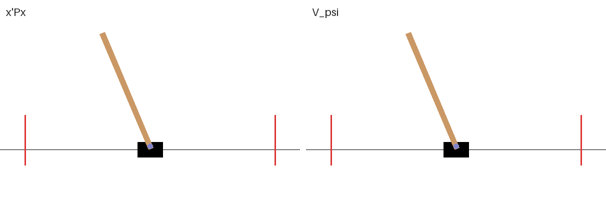

N = 5, estado inicial [x, x', theta, theta'] = [0.0, -0.43, 0.5, 0.0]
  x'Px   sale del riel  duró 1.16 s   solve: medio 3.9 ms, máximo 6.1 ms
  V_psi  estabiliza     duró 5.00 s   solve: medio 5.2 ms, máximo 17.1 ms


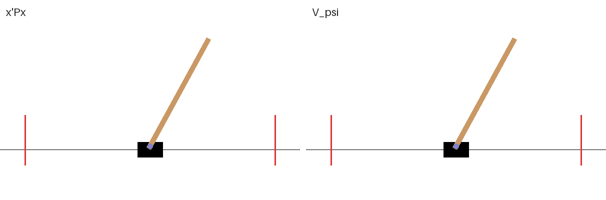

In [6]:
ESCENARIOS = [  # (N, theta0 [rad], v0 [m/s])
    (1, -0.2,  1.5),
    (2,  0.3,  3 / 14),
    (3, -0.4,  0.0),
    (5,  0.5, -3 / 7),
]

tiempos_por_escenario = []
for N, theta0, v0 in ESCENARIOS:
    tiempos_por_escenario.append(comparar(N, v0=v0, theta0=theta0))

## Tiempo de inferencia

La red agrega una MLP $4 \to 64 \to 64 \to 1$ dentro del costo terminal, así que Ipopt evalúa más cosas por iteración. Lo que importa es que el `solve` entre holgado en el período de control de 20 ms.
Ojo: en estos escenarios el promedio del clásico se toma solo sobre el ~0.5 s que dura antes de salirse del riel.

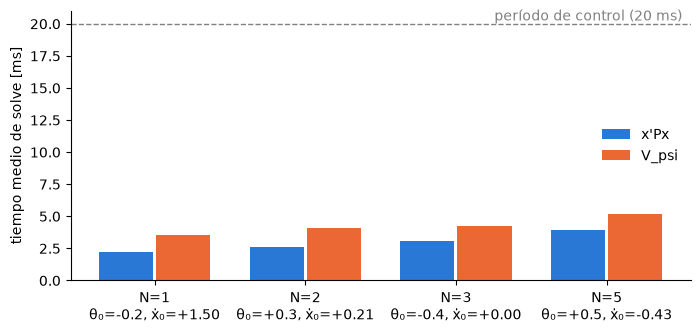

x'Px   medio 3.1 ms   mediana 2.8 ms   máximo 6.1 ms
V_psi  medio 4.3 ms   mediana 3.9 ms   máximo 17.1 ms


In [7]:
nombres = list(COSTOS_TERMINALES)
etiquetas = [f"N={N}\nθ₀={th:+.1f}, ẋ₀={v:+.2f}" for N, th, v in ESCENARIOS]
posiciones = np.arange(len(ESCENARIOS))
colores = {"x'Px": "#2a78d6", "V_psi": "#eb6834"}

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, nombre in enumerate(nombres):
    medias = [1e3 * t[nombre].mean() for t in tiempos_por_escenario]
    ax.bar(posiciones + (k - 0.5) * 0.38, medias, width=0.36, color=colores[nombre], label=nombre)
ax.axhline(1e3 * p.dt, color="gray", ls="--", lw=1)
ax.text(len(ESCENARIOS) - 0.5, 1e3 * p.dt, "período de control (20 ms)", ha="right", va="bottom", color="gray")
ax.set_xticks(posiciones, etiquetas)
ax.set_ylabel("tiempo medio de solve [ms]")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

for nombre in nombres:
    todos = np.concatenate([t[nombre] for t in tiempos_por_escenario])
    print(f"{nombre:6s} medio {1e3 * todos.mean():.1f} ms   mediana {1e3 * np.median(todos):.1f} ms   máximo {1e3 * todos.max():.1f} ms")

## Probá vos

Elegí el estado inicial y el horizonte, y apretá **Run Interact**. Cada corrida tarda unos segundos (dos MPC de hasta 250 pasos, con render).

In [ ]:
def probar(N, x0, v0, theta0, omega0):
    comparar(N, x0, v0, theta0, omega0)

widgets.interact_manual(
    probar,
    N=widgets.IntSlider(value=1, min=1, max=10, description="N"),
    x0=widgets.FloatSlider(value=0.0, min=-0.4, max=0.4, step=0.05, description="x₀ [m]"),
    v0=widgets.FloatSlider(value=1.5, min=-2.0, max=2.0, step=0.1, description="ẋ₀ [m/s]"),
    theta0=widgets.FloatSlider(value=-0.2, min=-0.7, max=0.7, step=0.05, description="θ₀ [rad]"),
    omega0=widgets.FloatSlider(value=0.0, min=-3.0, max=3.0, step=0.1, description="θ̇₀ [rad/s]"),
);

interactive(children=(IntSlider(value=1, description='N', max=10, min=1), FloatSlider(value=0.0, description='…